# Day 6 — Notebook 01b: StreamPulse Churn Class Balance (70 / 30)

**Goal:** See how StreamPulse customers split between **retained (`churned = 0`)** and **churned (`churned = 1`)**, and understand why this imbalance matters before we train any model.

**Action:** Click **Run → Run All Cells**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.read_csv("data/customers_raw.csv")

# Count each class and convert to percentages
counts = customers["churned"].value_counts().sort_index()   # 0 = retained, 1 = churned
pct = counts / counts.sum() * 100

print(f"Total rows        : {counts.sum():,}")
print(f"Missing 'churned' : {customers['churned'].isna().sum()}")
pd.DataFrame({"customers": counts, "percent": pct.round(1)}).rename(index={0: "Retained (0)", 1: "Churned (1)"})

Total rows        : 1,003
Missing 'churned' : 0


,customers,percent
churned,,
Retained (0),707,70.5
Churned (1),296,29.5


## Part 1: Visualize the 70 / 30 Split

Horizontal bars on a fixed 0–100% axis make the imbalance obvious at a glance (and are easier to compare than a pie chart).

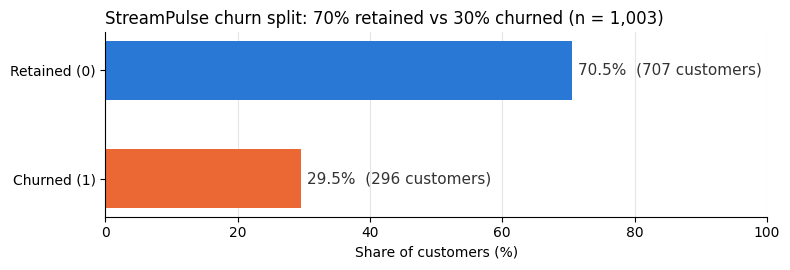

In [2]:
labels = ["Retained (0)", "Churned (1)"]
colors = ["#2a78d6", "#eb6834"]                              # blue = stays, orange = leaves

fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(labels, pct.values, color=colors, height=0.55)

# Print the % and the customer count at the end of each bar
for bar, p, n in zip(bars, pct.values, counts.values):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f"{p:.1f}%  ({n:,} customers)", va="center", fontsize=11, color="#333333")

ax.set_xlim(0, 100)
ax.set_xlabel("Share of customers (%)")
ax.set_title(f"StreamPulse churn split: {pct[0]:.0f}% retained vs {pct[1]:.0f}% churned "
             f"(n = {counts.sum():,})", loc="left", fontsize=12)
ax.invert_yaxis()                                            # Retained on top
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Part 2: Why Accuracy Alone Is Misleading

A "dumb" model that always predicts **nobody churns** gets the majority-class share as its accuracy — while catching **zero** churners.

In [3]:
dumb_accuracy = pct[0]
print(f"'Nobody churns' model accuracy : {dumb_accuracy:.1f}%")
print(f"Churners it catches (recall)   : 0 of {counts[1]:,}  ->  0.0%")

'Nobody churns' model accuracy : 70.5%
Churners it catches (recall)   : 0 of 296  ->  0.0%


### Key Takeaway
- StreamPulse data is **imbalanced (~70% retained / ~30% churned)**.
- Any model must beat the **~70% accuracy baseline** to be useful — so we track **Precision, Recall, F1, and ROC-AUC**, not accuracy alone.
- When splitting train/test later, use `stratify=y` so both sets keep this same 70 / 30 ratio.
- Total is 1,003 rows (not a round 1,000): the raw file is intentionally messy — Module 2 validation will catch duplicates.